# Clase 4 — Planificar con mapa: iteración de valor y de política

**RL a ciegas** · curso de aprendizaje por refuerzo (*reinforcement learning*, RL) · vía profunda

Basado en Sutton & Barto, cap. 3 (3.1 MDP, ejemplo 3.3 del robot de reciclaje, 3.6 optimalidad) y cap. 4 (4.1–4.4: evaluación, mejora e iteración de política, iteración de valor), y en Stanford CS234 (Brunskill), clase 2.

**La pregunta de hoy:** si conocieras el mapa entero de la cueva, ¿cómo calcularías la mejor flecha para cada casilla sin jugar ni una vez?

En la clase 3 el caminante tiraba un dado. Hoy **elige**. Vamos a ver:

1. **El MDP de la cueva**: $P(s' \mid s, a)$ para cada acción.
2. **Con la política fija** vuelve a ser una cadena: $P^\pi$ y el $V(S)$ de la clase 3.
3. **Cuánto vale cada acción**: $Q^\pi(s, a)$ en una casilla.
4. **Mejorar la política**: quedarse con la mejor acción.
5. **Iteración de política**: evaluar, mejorar, repetir.
6. **Iteración de valor**: el máximo en cada vuelta.
7. **Piso resbaloso, costo por paso y $\gamma$.**
8. **El robot de reciclaje**: el mismo molde fuera de la cueva.

Y un ejercicio: plantear y resolver su propio MDP chiquito.

> Cómo usar este notebook: ejecutar las celdas en orden (Colab: *Entorno de ejecución → Ejecutar todas*). Tarda menos de un minuto.

## Preparación

La primera celda escribe el archivo `cave_env.py` con **la cueva** de todo el curso. Así el notebook funciona solo, también en Colab. No hace falta leerla.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Importamos la cueva y las bibliotecas de siempre, y fijamos una semilla para que todos veamos los mismos resultados. Usamos las mismas convenciones que en la clase 3: **+1 al entrar a la salida**, la salida es absorbente y vale 0 (ahí ya no queda nada por cobrar), el primer paso no se descuenta y $\gamma = 0{,}99$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

SEMILLA = 0
np.random.seed(SEMILLA)
GAMMA = 0.99

La celda siguiente define las **herramientas** (evaluar una política, iteración de política y de valor, partidas y dibujos). Está plegada: no hace falta leerla, solo ejecutarla.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import matplotlib.patheffects as pe
from matplotlib.colors import ListedColormap

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5,
    "lines.linewidth": 2, "axes.axisbelow": True,
})
FLECHA = {0: "↑", 1: "→", 2: "↓", 3: "←"}


# ---------- políticas y evaluación ----------
def politica_azar(env):
    """pi[s, a] = 1/4: el dado de la clase 3."""
    return np.full((env.nS, env.nA), 1.0 / env.nA)


def como_tabla(env, pol):
    """Una política determinista (una flecha por casilla) como tabla pi[s, a] de ceros y unos."""
    pol = np.asarray(pol)
    return np.eye(env.nA)[pol] if pol.ndim == 1 else pol


def cadena_de(env, pi):
    """Con la política fija, el MDP es un MRP: P^pi[s, s'] = sum_a pi(a|s) P(s'|s,a) y R^pi[s] = sum_a pi(a|s) R(s,a)."""
    pi = como_tabla(env, pi)
    return np.einsum("sa,sat->st", pi, env.P), (pi * env.R).sum(axis=1)


def evaluar(env, pi, gamma):
    """V^pi exacto: la ecuación de Bellman del MRP, V = R^pi + gamma P^pi V, resuelta de un saque."""
    Ppi, Rpi = cadena_de(env, pi)
    if gamma < 1:
        V = np.linalg.solve(np.eye(env.nS) - gamma * Ppi, Rpi)
        return np.where(np.abs(V) < 1e-15, 0.0, V)        # sin «-0» por redondeo
    V = np.zeros(env.nS)                       # gamma = 1: iterar (la salida corta las partidas)
    for _ in range(100_000):
        V_nuevo = Rpi + Ppi @ V
        if np.max(np.abs(V_nuevo - V)) < 1e-12:
            break
        V = V_nuevo
    return V_nuevo


def valores_Q(env, V, gamma):
    """Q[s, a] = R(s,a) + gamma * sum_s' P(s'|s,a) V(s')."""
    return env.R + gamma * env.P @ V


def mejorar(env, Q, vieja=None):
    """En cada casilla, la flecha de mayor Q. Si la flecha vieja empata con la mejor, se queda (así no oscila)."""
    nueva = Q.argmax(axis=1)
    if vieja is not None:
        vieja = np.asarray(vieja)
        empata = np.isclose(Q[np.arange(env.nS), vieja], Q.max(axis=1), rtol=0, atol=1e-12)
        nueva[empata] = vieja[empata]
    return nueva


def iteracion_de_politica(env, gamma, pi0):
    """Evaluar -> mejorar -> repetir hasta que ninguna flecha cambia.
    pi0 puede ser una tabla pi[s, a] (por ejemplo, el dado) o una flecha por casilla.
    Devuelve la lista de vueltas: en cada una, la política evaluada, su V y la política mejorada."""
    pol, vueltas = pi0, []
    while True:
        V = evaluar(env, pol, gamma)
        vieja = None if np.ndim(pol) == 2 else pol
        nueva = mejorar(env, valores_Q(env, V, gamma), vieja)
        cambian = env.nS if vieja is None else int(np.sum(nueva != vieja))
        vueltas.append({"pol": pol, "V": V, "nueva": nueva, "cambian": cambian})
        if vieja is not None and cambian == 0:
            return vueltas
        pol = nueva


def iteracion_de_valor(env, gamma, tol=1e-10, max_vueltas=100_000):
    """V_0 = 0;  V_{k+1}(s) = max_a [R(s,a) + gamma sum_s' P(s'|s,a) V_k(s')].
    Para cuando el cambio máximo de una vuelta es menor que tol. Devuelve la historia [V_0, V_1, ...]."""
    V = np.zeros(env.nS); hist = [V.copy()]
    for _ in range(max_vueltas):
        V_nuevo = valores_Q(env, V, gamma).max(axis=1)
        hist.append(V_nuevo.copy())
        if np.max(np.abs(V_nuevo - V)) < tol:
            break
        V = V_nuevo
    return hist


def acciones_optimas(env, gamma):
    """Máscara [s, a]: True si a es óptima en s (puede haber empates)."""
    V = iteracion_de_valor(env, gamma)[-1]
    Q = valores_Q(env, V, gamma)
    return np.isclose(Q, Q.max(axis=1, keepdims=True), rtol=0, atol=1e-9)


def frac_optimas(env, pol, opt):
    """Fracción de casillas (sin la salida) cuya flecha es óptima."""
    ss = [s for s in range(env.nS) if s != env.goal]
    return float(np.mean([opt[s, pol[s]] for s in ss]))


def partida(env, pol, semilla=0, max_pasos=200):
    """Una partida desde S siguiendo la política; con slip, los resbalones salen de P(s'|s,a)."""
    rng = np.random.default_rng(semilla)
    s = env.start; camino = [s]
    for _ in range(max_pasos):
        s = int(rng.choice(env.nS, p=env.P[s, int(pol[s])])); camino.append(s)
        if s == env.goal:
            break
    return camino


def distancias(env):
    """Pasos mínimos desde cada casilla hasta la salida (búsqueda en anchura hacia atrás)."""
    d = np.full(env.nS, -1); d[env.goal] = 0; frente = [env.goal]
    while frente:
        nuevo = []
        for s in frente:
            for s2 in range(env.nS):
                if d[s2] < 0 and any(env._move(s2, a)[0] == s for a in range(4)):
                    d[s2] = d[s] + 1; nuevo.append(s2)
        frente = nuevo
    return d


def log10_seguro(v, piso=1e-15):
    v = np.asarray(v, dtype=float)
    out = np.full_like(v, np.nan); m = v > piso
    out[m] = np.log10(v[m])
    return out


def mostrar_transiciones(env, s):
    """Desde la casilla s, para cada acción: adónde puede ir, con qué probabilidad y qué premio espera."""
    print(f"Casilla {env.free[s]}:")
    for a in range(env.nA):
        dest = ", ".join(f"{env.free[s2]} con {p:.2f}" + (" (choca y se queda)" if s2 == s else "")
                         for s2, p in enumerate(env.P[s, a]) if p > 0)
        print(f"   {FLECHA[a]}  ->  {dest}   R(s,{FLECHA[a]}) = {env.R[s, a]:+.2f}")


# ---------- dibujos de la cueva ----------
def plot_cave(env, values=None, policy=None, path=None, ax=None, title=None, cmap="magma", clim=None,
              mark=None, numbers=False, fmt="{:.2f}"):
    """env.plot + escala de color elegible (calculada sin la salida), flechas con borde, círculo y números opcionales."""
    ax = env.plot(values=values, policy=policy, path=path, ax=ax, title=title, cmap=cmap)
    if values is not None:
        if clim is None:
            v = np.asarray(values, dtype=float)[np.arange(env.nS) != env.goal]
            v = v[np.isfinite(v)]
            clim = (v.min(), v.max()) if v.size else (0, 1)
            if clim[1] - clim[0] < 1e-12:
                clim = (clim[1] - 1, clim[1])
        ax.images[-1].set_clim(*clim)
    for t in ax.texts:
        t.set_path_effects([pe.withStroke(linewidth=2.5, foreground="black")])
    if mark is not None:
        r, c = env.free[mark]
        ax.plot(c, r, "o", mfc="none", mec="#00e5ff", mew=2.5, ms=15)
    if numbers and values is not None:
        for s, (r, c) in enumerate(env.free):
            if np.isfinite(values[s]) and s != env.goal:
                ax.text(c, r + 0.3, fmt.format(values[s]), ha="center", va="center", fontsize=7, color="w",
                        path_effects=[pe.withStroke(linewidth=2, foreground="black")])
    return ax


def plot_row(env, values_list, titles, policies=None, cmap="magma", clim=None, size=4.2, ncols=None, marks=None):
    n = len(values_list)
    ncols = n if ncols is None else ncols
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, (size * env.H / env.W + 0.6) * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    for i, ax in enumerate(axes[:n]):
        plot_cave(env, values=values_list[i], ax=ax, title=titles[i], cmap=cmap, clim=clim,
                  policy=None if policies is None else policies[i], mark=None if marks is None else marks[i])
    plt.tight_layout(); plt.show()


def partidas_superpuestas(env, caminos, ax, color, titulo):
    """Dibuja varias partidas sobre la cueva; cada una corrida un poquito para que se distingan."""
    plot_cave(env, ax=ax, title=titulo)
    n = len(caminos)
    for i, cam in enumerate(caminos):
        rc = np.array([env.free[s] for s in cam], dtype=float)
        dx = (i - (n - 1) / 2) * 0.035
        ax.plot(rc[:, 1] + dx, rc[:, 0] + dx, "-", color=color, lw=1.4, alpha=0.75)


# ---------- MDP chicos (robot de reciclaje y el ejercicio) ----------
def armar_mdp(estados, acciones, transicion):
    """transicion(s, a) -> lista de (probabilidad, s_siguiente, recompensa); lista vacía = acción no permitida.
    Devuelve P[s, a, s'], R[s, a] (recompensa esperada) y la máscara de acciones permitidas."""
    S, A = len(estados), len(acciones); pos = {s: i for i, s in enumerate(estados)}
    P = np.zeros((S, A, S)); R = np.zeros((S, A)); valida = np.zeros((S, A), bool)
    for s in estados:
        for j, a in enumerate(acciones):
            res = transicion(s, a)
            if not res:
                continue
            valida[pos[s], j] = True
            assert abs(sum(p for p, _, _ in res) - 1) < 1e-9, f"las probabilidades de ({s}, {a}) no suman 1"
            for p, s2, r in res:
                P[pos[s], j, pos[s2]] += p; R[pos[s], j] += p * r
    return P, R, valida


def resolver_chico(P, R, valida, gamma, tol=1e-10):
    """Iteración de valor con acciones no permitidas (Q = -inf). Devuelve V*, la política, Q y las vueltas."""
    V = np.zeros(P.shape[0]); k = 0
    while True:
        Q = np.where(valida, R + gamma * P @ V, -np.inf)
        V_nuevo = Q.max(axis=1); k += 1
        if np.max(np.abs(V_nuevo - V)) < tol:
            return V_nuevo, Q.argmax(axis=1), Q, k
        V = V_nuevo


def iteracion_de_politica_chica(P, R, valida, gamma):
    """Iteración de política en un MDP chico: arranca con la primera acción permitida de cada estado."""
    S = P.shape[0]; pol = valida.argmax(axis=1); k = 0
    while True:
        idx = np.arange(S)
        V = np.linalg.solve(np.eye(S) - gamma * P[idx, pol], R[idx, pol])
        Q = np.where(valida, R + gamma * P @ V, -np.inf)
        nueva = Q.argmax(axis=1); k += 1
        empata = np.isclose(Q[idx, pol], Q.max(axis=1), rtol=0, atol=1e-12)
        nueva[empata] = pol[empata]
        if np.array_equal(nueva, pol):
            return V, pol, k
        pol = nueva


def resolver_mdp(estados, acciones, transicion, gamma=0.9, mostrar=True):
    """Arma el MDP, lo resuelve con iteración de valor y de política, e imprime la tabla de la política."""
    P, R, valida = armar_mdp(estados, acciones, transicion)
    V, pol, Q, k_vi = resolver_chico(P, R, valida, gamma)
    V_pi, pol_pi, k_pi = iteracion_de_politica_chica(P, R, valida, gamma)
    if mostrar:
        ancho = max(len(str(s)) for s in estados) + 2
        print(f"{'estado':<{ancho}} {'acción óptima':<15} {'V*(s)':>8}   " + "   ".join(f"Q(s, {a})" for a in acciones))
        for i, s in enumerate(estados):
            qs = "   ".join(f"{Q[i, j]:>{len(a) + 6}.2f}" if valida[i, j] else f"{'—':>{len(a) + 6}}"
                           for j, a in enumerate(acciones))
            print(f"{str(s):<{ancho}} {acciones[pol[i]]:<15} {V[i]:>8.2f}   {qs}")
        igual = np.allclose(V, V_pi, atol=1e-6)
        print(f"\niteración de valor: {k_vi} vueltas · iteración de política: {k_pi} vueltas · "
              f"¿mismo V*? {'sí' if igual else 'no'}")
    return {"V": V, "pol": [acciones[k] for k in pol], "Q": Q, "valida": valida}


# ---------- el robot de reciclaje (Sutton y Barto, ejemplo 3.3) ----------
def robot(alfa=0.8, beta=0.4, r_buscar=2.0, r_esperar=1.0, r_rescate=-3.0):
    """Batería alta o baja; buscar latas, esperar a que se las traigan o recargar (solo con batería baja)."""
    def transicion(s, a):
        if a == "buscar":
            if s == "alta":
                return [(alfa, "alta", r_buscar), (1 - alfa, "baja", r_buscar)]
            return [(beta, "baja", r_buscar), (1 - beta, "alta", r_rescate)]   # se agota: lo rescatan y lo recargan
        if a == "esperar":
            return [(1.0, s, r_esperar)]
        if a == "recargar":
            return [(1.0, "alta", 0.0)] if s == "baja" else []
    return ["alta", "baja"], ["buscar", "esperar", "recargar"], transicion


def robot_resuelto(gamma=0.9, **kw):
    est, acc, tr = robot(**kw)
    P, R, valida = armar_mdp(est, acc, tr)
    V, pol, Q, _ = resolver_chico(P, R, valida, gamma)
    return V, [acc[k] for k in pol], Q


def umbral_beta(gamma=0.9, alfa=0.8, r_buscar=2.0, r_esperar=1.0, r_rescate=-3.0):
    """El β a partir del cual, con batería baja, conviene buscar en vez de recargar (bisección)."""
    def accion(b):
        return robot_resuelto(gamma, alfa=alfa, beta=b, r_buscar=r_buscar, r_esperar=r_esperar, r_rescate=r_rescate)[1][1]
    lo, hi = 0.0, 1.0
    if accion(lo) == "buscar" or accion(hi) != "buscar":
        return np.nan
    for _ in range(50):
        m = (lo + hi) / 2
        lo, hi = (lo, m) if accion(m) == "buscar" else (m, hi)
    return (lo + hi) / 2


def mapa_robot(gamma=0.9, alfa=0.8, r_buscar=2.0, r_rescate=-3.0):
    """Acción óptima con batería BAJA según β (eje x) y la recompensa por esperar (eje y)."""
    betas = np.linspace(0, 1, 81); esperas = np.linspace(0, 2.5, 51)
    nombres = ["buscar", "esperar", "recargar"]
    acc = np.zeros((len(esperas), len(betas)))
    for i, rw in enumerate(esperas):
        for j, b in enumerate(betas):
            acc[i, j] = nombres.index(robot_resuelto(gamma, alfa=alfa, beta=b, r_buscar=r_buscar,
                                                     r_esperar=rw, r_rescate=r_rescate)[1][1])
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    ax.imshow(acc, origin="lower", cmap=ListedColormap([COLORES[2], COLORES[3], COLORES[0]]), vmin=-0.5, vmax=2.5,
              aspect="auto", extent=[betas[0], betas[-1], esperas[0], esperas[-1]])
    ax.grid(False)
    for k, nombre in enumerate(nombres):
        if (acc == k).any():
            yy, xx = np.argwhere(acc == k).mean(0)
            x = betas[int(xx)]
            angosta = x > 0.8                                   # región angosta: texto vertical
            ax.text(x, esperas[int(yy)], nombre, ha="center", va="center", rotation=90 if angosta else 0,
                    color="white", fontsize=12 if angosta else 14, weight="bold")
    ax.set_xlabel("β: probabilidad de NO agotarse buscando con batería baja")
    ax.set_ylabel("recompensa por esperar")
    ax.set_title(f"Acción óptima con batería BAJA (α = {alfa}, buscar rinde {r_buscar:g}, γ = {gamma})")
    plt.show()

## 1. El MDP de la cueva: $P(s' \mid s, a)$ por acción

En la clase 3 el caminante tiraba un dado de cuatro caras. Ahora, en cada casilla, **elige** una de cuatro acciones (↑ → ↓ ←). Una cadena de Markov con recompensa **y acciones** se llama **proceso de decisión de Markov** (*Markov decision process*, MDP). Se describe con cinco cosas:

$$(S,\ A,\ P,\ R,\ \gamma)$$

- $S$: las 60 casillas libres; $A$: las cuatro acciones;
- $P(s' \mid s, a)$: adónde va a parar si hace $a$ en $s$ (ahora hay **una tabla por acción**);
- $R(s, a)$: el premio que espera cobrar: +1 si ese paso entra a la salida, 0 si no;
- $\gamma$: el descuento de la clase 3.

### Paso 1 — Las tablas $P$ y $R$

`env.P` tiene tres índices: casilla de partida, acción y casilla de llegada. `env.R` tiene dos: casilla y acción.

In [4]:
env = CaveEnv()
print("casillas:", env.nS, "  acciones:", env.nA, ACTION_NAMES)
print("P:", env.P.shape, "  R:", env.R.shape)
print("¿cada P[s, a, :] suma 1?", np.allclose(env.P.sum(axis=2), 1))
print("¿piso normal: cada acción lleva a una sola casilla?", np.all((env.P > 0).sum(axis=2) == 1))

casillas: 60   acciones: 4 ['↑', '→', '↓', '←']
P: (60, 4, 60)   R: (60, 4)
¿cada P[s, a, :] suma 1? True
¿piso normal: cada acción lleva a una sola casilla? True


### Paso 2 — Una casilla, cuatro destinos

Tomemos un cruce, la casilla de la fila 5, columna 6 (solo arriba hay pared). Para cada acción, $P(s' \mid \text{cruce}, a)$ es una distribución sobre las casillas de llegada. Con piso normal, toda la probabilidad cae en un solo lugar.

Casilla (5, 6):
   ↑  ->  (5, 6) con 1.00 (choca y se queda)   R(s,↑) = +0.00
   →  ->  (5, 7) con 1.00   R(s,→) = +0.00
   ↓  ->  (6, 6) con 1.00   R(s,↓) = +0.00
   ←  ->  (5, 5) con 1.00   R(s,←) = +0.00

Casilla (8, 11):
   ↑  ->  (7, 11) con 1.00   R(s,↑) = +0.00
   →  ->  (8, 12) con 1.00   R(s,→) = +1.00
   ↓  ->  (8, 11) con 1.00 (choca y se queda)   R(s,↓) = +0.00
   ←  ->  (8, 10) con 1.00   R(s,←) = +0.00


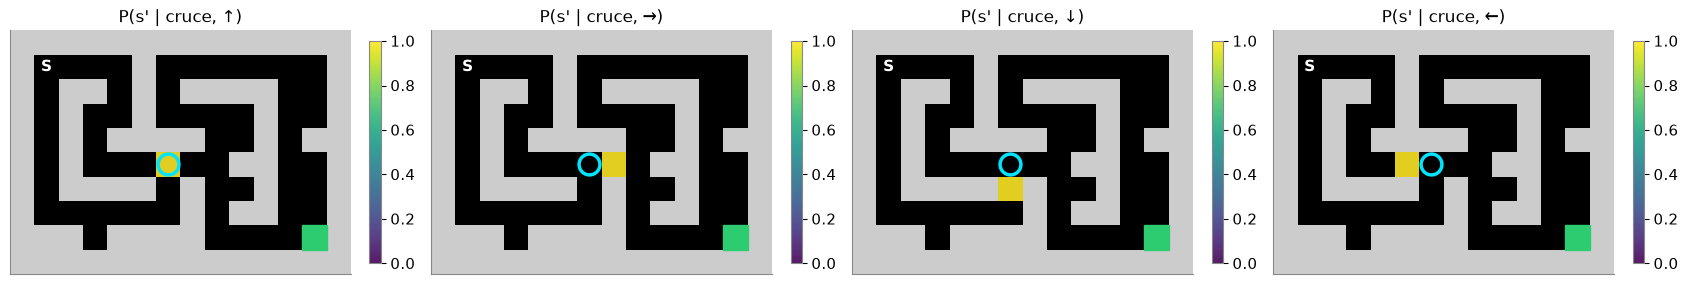

In [5]:
cruce = env.pos2s[(5, 6)]
mostrar_transiciones(env, cruce)
print()
izq_salida = env.pos2s[(8, 11)]
mostrar_transiciones(env, izq_salida)

fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
for a, ax in enumerate(axs):
    plot_cave(env, values=np.where(env.P[cruce, a] > 0, env.P[cruce, a], np.nan), ax=ax, cmap="viridis",
              clim=(0, 1), mark=cruce, title=f"P(s' | cruce, {ACTION_NAMES[a]})")
plt.tight_layout(); plt.show()

Desde el cruce, ↑ choca y se queda; las otras tres acciones mueven a una vecina. Al lado de la salida, la acción → entra y cobra $R = +1$. Lo que antes era **una** fila de $P$ (el promedio del dado) ahora son **cuatro**: una por acción. El que decide cuál se usa es el agente.

## 2. Con la política fija vuelve a ser una cadena: $P^\pi$ y el $V(S)$ de la clase 3

Una **política** (*policy*) $\pi(a \mid s)$ dice con qué probabilidad elegir cada acción en cada casilla (clase 2). Si la política está **fija**, en cada casilla queda una sola distribución de destinos: el promedio de las tablas de cada acción, pesado con la política.

$$P^\pi(s' \mid s) = \sum_a \pi(a \mid s)\, P(s' \mid s, a) \qquad R^\pi(s) = \sum_a \pi(a \mid s)\, R(s, a)$$

Un MDP con la política fija es un **MRP**, como el de la clase 3. Y con la política al azar ($\pi(a \mid s) = 1/4$, el dado) tiene que dar **exactamente** el caminante de la clase 3.

### Paso 1 — La política al azar recupera la clase 3

In [6]:
pi_azar = politica_azar(env)
P_azar, R_azar = cadena_de(env, pi_azar)
P_clase3, R_clase3 = env.P.mean(axis=1), env.R.mean(axis=1)      # la cadena del dado, como en la clase 3
print("¿P^π igual a la P del caminante de la clase 3?", np.allclose(P_azar, P_clase3))
print("¿R^π igual a la R de la clase 3?", np.allclose(R_azar, R_clase3))
print("Fila de P^π de S:", ", ".join(f"{env.free[s2]}: {P_azar[env.start, s2]:.2f}" for s2 in np.flatnonzero(P_azar[env.start])))

V_azar = evaluar(env, pi_azar, GAMMA)                             # V = (I − γ P^π)^(-1) R^π
print(f"\nV(S) con la política al azar, γ = {GAMMA}:  {V_azar[env.start]:.5f}  ≈ {V_azar[env.start]:.4f}  (el mismo de la clase 3)")
print(f"V(cruce) = {V_azar[cruce]:.4f}    V(salida) = {V_azar[env.goal]:.0f}")

¿P^π igual a la P del caminante de la clase 3? True
¿R^π igual a la R de la clase 3? True
Fila de P^π de S: (1, 1): 0.50, (1, 2): 0.25, (2, 1): 0.25

V(S) con la política al azar, γ = 0.99:  0.01359  ≈ 0.0136  (el mismo de la clase 3)
V(cruce) = 0.0771    V(salida) = 0


### Paso 2 — El mapa de valor del dado

Pintamos $\log_{10} V^\pi$ como en la clase 3 (el valor cae muchísimo hacia el fondo de la cueva). Al lado, una política fija **determinista** cualquiera, «todas ↑»: también es una cadena, con una sola flecha por casilla. Como ninguna flecha ↑ entra a la salida, nadie cobra nunca nada y todo vale 0.

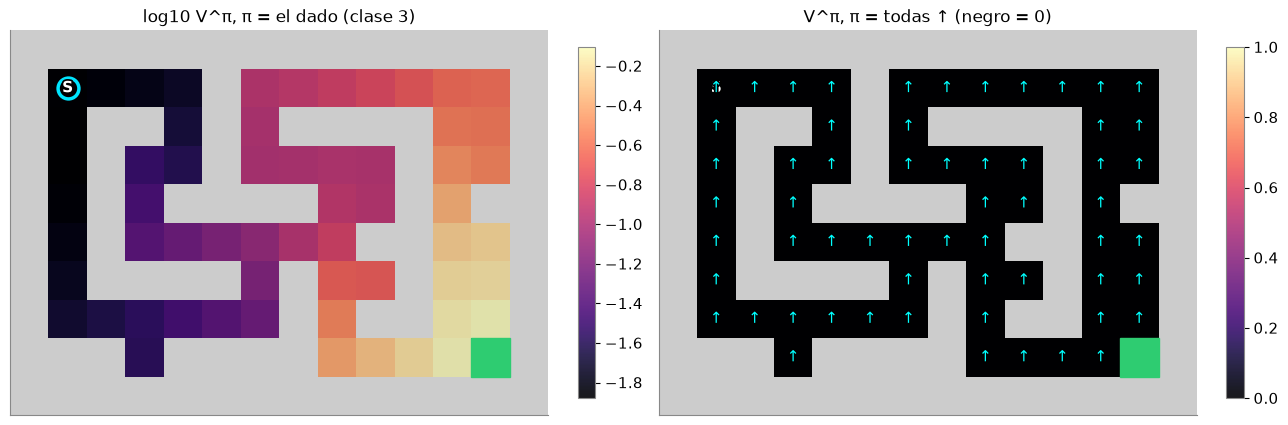

todas ↑: V(S) = 0,  máximo de V = 0


In [7]:
todas_arriba = np.zeros(env.nS, dtype=int)
V_arriba = evaluar(env, todas_arriba, GAMMA)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
plot_cave(env, values=log10_seguro(V_azar), ax=axs[0], mark=env.start, title="log10 V^π, π = el dado (clase 3)")
plot_cave(env, values=V_arriba, policy=todas_arriba, ax=axs[1], clim=(0, 1), title="V^π, π = todas ↑ (negro = 0)")
plt.tight_layout(); plt.show()
print(f"todas ↑: V(S) = {V_arriba[env.start]:.0f},  máximo de V = {V_arriba.max():.0f}")

Evaluar una política fija no tiene nada nuevo: es la ecuación de Bellman de la clase 3 con $P^\pi$ y $R^\pi$. Lo nuevo empieza cuando preguntamos qué pasaría si, en una casilla, hiciéramos otra cosa.

## 3. Cuánto vale cada acción: $Q^\pi(s, a)$ en una casilla

El **valor de una acción** (*action value*) responde: *¿y si acá hago esto, y después sigo como venía?* Es el premio de este paso más el valor descontado de adonde voy a parar, siguiendo después la política $\pi$:

$$Q^\pi(s, a) = R(s, a) + \gamma \sum_{s'} P(s' \mid s, a)\, V^\pi(s')$$

### Paso 1 — Las cuatro acciones del cruce

Con los valores del dado (la política al azar), calculemos $Q^\pi$ de las cuatro acciones en el cruce.

Cruce (5, 6), política al azar, γ = 0.99:
   Q(cruce, ↑) = R + γ·V(5, 6) = 0 + 0.99·0.0771 = 0.0763
   Q(cruce, →) = R + γ·V(5, 7) = 0 + 0.99·0.1081 = 0.1070
   Q(cruce, ↓) = R + γ·V(6, 6) = 0 + 0.99·0.0629 = 0.0623
   Q(cruce, ←) = R + γ·V(5, 5) = 0 + 0.99·0.0633 = 0.0627
   promedio de las cuatro = 0.0771 = V^π(cruce) = 0.0771
   la mejor: →


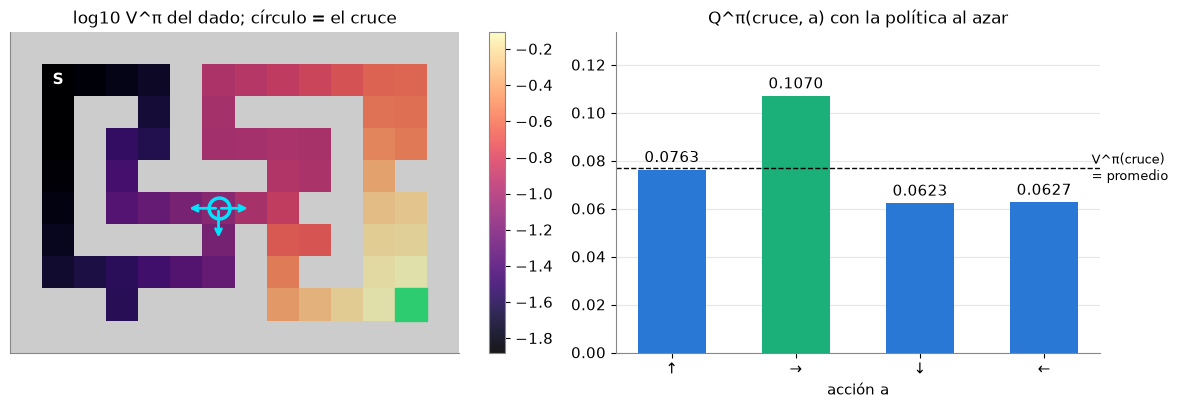

In [8]:
Q_azar = valores_Q(env, V_azar, GAMMA)
print(f"Cruce {env.free[cruce]}, política al azar, γ = {GAMMA}:")
for a in range(env.nA):
    s2 = int(np.argmax(env.P[cruce, a]))
    print(f"   Q(cruce, {ACTION_NAMES[a]}) = R + γ·V{env.free[s2]} = {env.R[cruce, a]:.0f} + {GAMMA}·{V_azar[s2]:.4f} = {Q_azar[cruce, a]:.4f}")
print(f"   promedio de las cuatro = {Q_azar[cruce].mean():.4f} = V^π(cruce) = {V_azar[cruce]:.4f}")
print(f"   la mejor: {ACTION_NAMES[int(Q_azar[cruce].argmax())]}")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
plot_cave(env, values=log10_seguro(V_azar), ax=axs[0], mark=cruce, title="log10 V^π del dado; círculo = el cruce")
for a in range(env.nA):
    s2 = int(np.argmax(env.P[cruce, a]))
    if s2 != cruce:
        (r, c), (r2, c2) = env.free[cruce], env.free[s2]
        axs[0].annotate("", xy=(c2, r2), xytext=(c, r), arrowprops=dict(arrowstyle="->", color="#00e5ff", lw=2))
bars = axs[1].bar(ACTION_NAMES, Q_azar[cruce], color=[COLORES[2] if a == Q_azar[cruce].argmax() else COLORES[0]
                                                       for a in range(env.nA)], width=0.55)
axs[1].bar_label(bars, fmt="%.4f", padding=3)
axs[1].axhline(V_azar[cruce], color="k", ls="--", lw=1)
axs[1].text(3.35, V_azar[cruce], " V^π(cruce)\n = promedio", va="center", fontsize=9)
axs[1].set_ylim(0, Q_azar[cruce].max() * 1.25); axs[1].grid(axis="x", visible=False)
axs[1].set_title("Q^π(cruce, a) con la política al azar"); axs[1].set_xlabel("acción a")
plt.tight_layout(); plt.show()

Ir → (hacia la salida) vale más que las otras tres; ↑ choca y se queda, así que vale casi lo mismo que estar en el cruce. Y una cuenta que vale la pena mirar: como el dado elige las cuatro con la misma probabilidad, **el promedio de las cuatro $Q$ es exactamente $V^\pi$**.

### Paso 2 — En todas las casillas

La misma cuenta en todas las casillas da una tabla $Q^\pi$ de 60 × 4. Para cada acción, pintamos de naranja las casillas donde $Q^\pi(s, a) > V^\pi(s)$, es decir, donde «esta acción es mejor que tirar el dado acá», y de azul donde es peor.

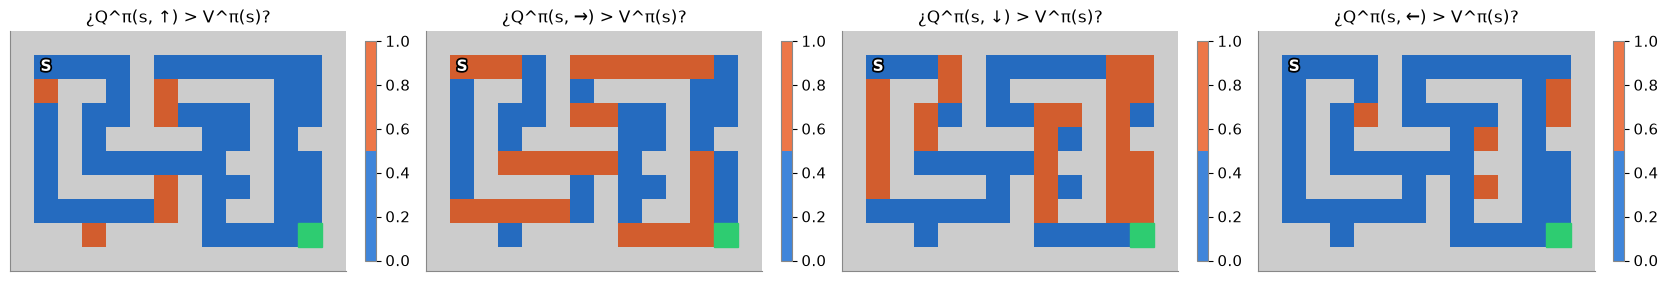

Casillas con al menos una acción mejor que el dado: 59 de 59
En S:  Q(S, ↑) = 0.01345   Q(S, →) = 0.01437   Q(S, ↓) = 0.01307   Q(S, ←) = 0.01345   V^π(S) = 0.01359


In [9]:
mejor_que_dado = np.where(np.arange(env.nS)[:, None] != env.goal, (Q_azar > V_azar[:, None]).astype(float), np.nan)
plot_row(env, [mejor_que_dado[:, a] for a in range(env.nA)], [f"¿Q^π(s, {ACTION_NAMES[a]}) > V^π(s)?" for a in range(env.nA)],
         cmap=ListedColormap([COLORES[0], COLORES[1]]), clim=(0, 1), size=4.2, ncols=4)
otras = np.arange(env.nS) != env.goal
print(f"Casillas con al menos una acción mejor que el dado: {int(mejor_que_dado[otras].max(axis=1).sum())} de {env.nS - 1}")
print(f"En S:  " + "   ".join(f"Q(S, {ACTION_NAMES[a]}) = {Q_azar[env.start, a]:.5f}" for a in range(env.nA))
      + f"   V^π(S) = {V_azar[env.start]:.5f}")

En cada casilla hay al menos una acción naranja: la que acerca a la salida. Tiene que ser así: si $V^\pi$ es el promedio de las cuatro $Q^\pi$, alguna está por encima del promedio (salvo que las cuatro sean iguales).

## 4. Mejorar: quedarse con la mejor acción

La **mejora de la política** (*policy improvement*): en cada casilla, poner la flecha de la mayor $Q^\pi$.

$$\pi'(s) = \arg\max_a\, Q^\pi(s, a)$$

La política nueva **nunca es peor** que la vieja: en ninguna casilla su valor baja (Sutton y Barto lo demuestran en 4.2; acá solo lo comprobamos).

### Paso 1 — Una mejora desde el dado

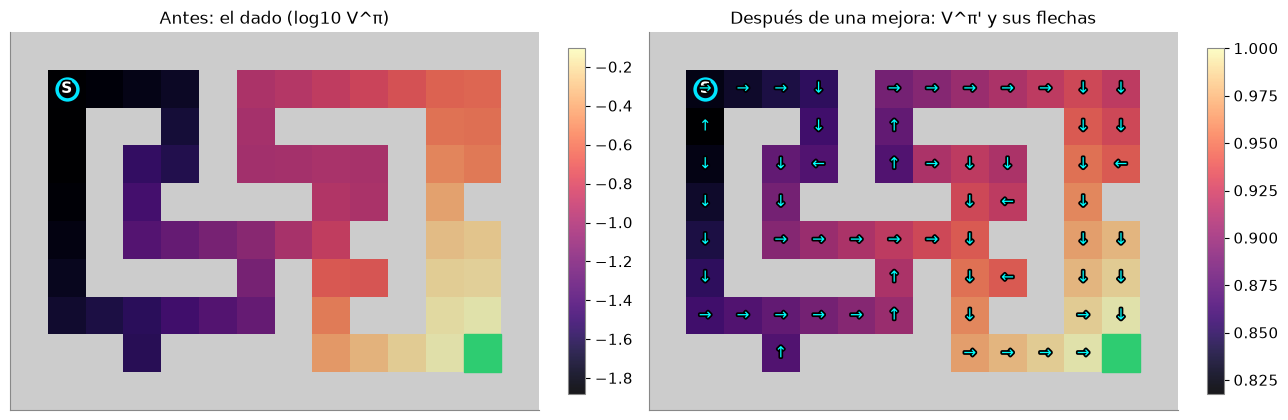

V(S):  antes = 0.0136   después de una mejora = 0.8262
¿En alguna casilla bajó el valor? no
Casillas donde subió: 59 de 59


In [10]:
pi_mejor = mejorar(env, Q_azar)
V_mejor = evaluar(env, pi_mejor, GAMMA)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
plot_cave(env, values=log10_seguro(V_azar), ax=axs[0], mark=env.start, title="Antes: el dado (log10 V^π)")
plot_cave(env, values=V_mejor, policy=pi_mejor, ax=axs[1], mark=env.start, title="Después de una mejora: V^π' y sus flechas")
plt.tight_layout(); plt.show()

print(f"V(S):  antes = {V_azar[env.start]:.4f}   después de una mejora = {V_mejor[env.start]:.4f}")
print(f"¿En alguna casilla bajó el valor? {'sí' if np.any(V_mejor < V_azar - 1e-12) else 'no'}")
print(f"Casillas donde subió: {int(np.sum(V_mejor > V_azar + 1e-12))} de {env.nS - 1}")

Una sola mejora y las flechas ya llevan de S a la salida: $V(S)$ pasa de 0,0136 a $0{,}99^{19}$, lo que vale ir derecho en 20 pasos. Esta cueva es benévola: el dado ya «ve» la salida desde todas partes, aunque débilmente, y eso alcanza para que las flechas apunten bien casi en todos lados. ¿Ya es la mejor política? Para saberlo hay que volver a evaluar y a mejorar.

## 5. Iteración de política: evaluar, mejorar, repetir

La **iteración de política** (*policy iteration*) repite dos pasos hasta que ninguna flecha cambia:

1. **Evaluar** la política actual de un saque: $V^\pi = (I - \gamma P^\pi)^{-1} R^\pi$ (sección 2).
2. **Mejorar**: $\pi'(s) = \arg\max_a Q^\pi(s, a)$ (secciones 3 y 4). Si la flecha vieja empata con la mejor, se queda.

Llamamos **vuelta** a un par evaluar + mejorar. La última vuelta solo confirma que nada cambia.

### Paso 1 — Desde el dado y desde «todas ↑»

In [11]:
pi_desde_azar = iteracion_de_politica(env, GAMMA, pi_azar)
pi_desde_arriba = iteracion_de_politica(env, GAMMA, todas_arriba)
opt = acciones_optimas(env, GAMMA)

for nombre, vueltas in [("el dado", pi_desde_azar), ("todas ↑", pi_desde_arriba)]:
    cambios = ["todas" if np.ndim(v["pol"]) == 2 else v["cambian"] for v in vueltas]   # el dado no tiene flechas
    print(f"Desde {nombre}: {len(vueltas)} vueltas ({len(vueltas) - 1} cambian flechas y la última confirma).")
    print(f"   flechas que cambian en cada vuelta: {cambios}")
    print(f"   V(S) al evaluar en cada vuelta: " + ", ".join(f"{v['V'][env.start]:.4f}" for v in vueltas))
    print(f"   ¿la política final es óptima en todas las casillas? {'sí' if frac_optimas(env, vueltas[-1]['nueva'], opt) == 1 else 'no'}")

Desde el dado: 4 vueltas (3 cambian flechas y la última confirma).
   flechas que cambian en cada vuelta: ['todas', 1, 1, 0]
   V(S) al evaluar en cada vuelta: 0.0136, 0.8262, 0.8262, 0.8262
   ¿la política final es óptima en todas las casillas? sí
Desde todas ↑: 21 vueltas (20 cambian flechas y la última confirma).
   flechas que cambian en cada vuelta: [2, 3, 3, 2, 2, 2, 4, 4, 5, 5, 4, 4, 3, 2, 2, 2, 2, 2, 2, 1, 0]
   V(S) al evaluar en cada vuelta: 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.8262
   ¿la política final es óptima en todas las casillas? sí


### Paso 2 — Vuelta por vuelta, desde «todas ↑»

Desde «todas ↑» todo vale 0, así que la primera mejora solo puede cambiar las flechas que **entran a la salida**: son las únicas acciones con $Q > 0$. Dibujamos $V^\pi$ y las flechas de la política evaluada en algunas vueltas (misma escala; negro = 0).

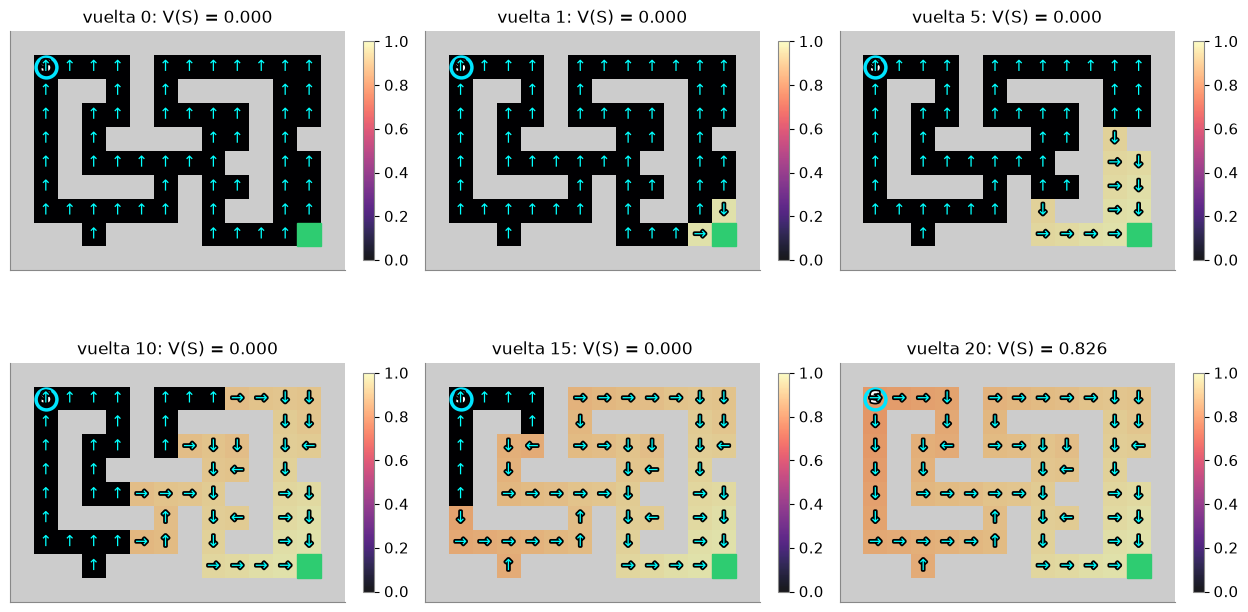

In [12]:
ks = [0, 1, 5, 10, 15, len(pi_desde_arriba) - 1]
plot_row(env, [pi_desde_arriba[k]["V"] for k in ks], [f"vuelta {k}: V(S) = {pi_desde_arriba[k]['V'][env.start]:.3f}" for k in ks],
         policies=[pi_desde_arriba[k]["pol"] for k in ks], clim=(0, 1), size=4.2, ncols=3, marks=[env.start] * len(ks))

Las flechas se acomodan **desde la salida hacia atrás**, un tramo por vuelta: en cada vuelta solo puede mejorar la casilla cuya vecina ya tiene valor. En un laberinto de pasillos como esta cueva, desde «todas ↑» hacen falta casi tantas vueltas como pasos hay hasta la casilla más lejana. Desde el dado, en cambio, alcanzaron pocas: el dado ya había repartido un poco de valor por toda la cueva.

## 6. Iteración de valor: el máximo en cada vuelta

En la clase 3 iterábamos $V_{k+1} = R + \gamma P V_k$ promediando las caras del dado. La **iteración de valor** (*value iteration*) cambia una sola cosa: en vez de promediar las acciones, **se queda con la mejor** en cada vuelta.

$$V_{k+1}(s) = \max_a \Big[R(s, a) + \gamma \sum_{s'} P(s' \mid s, a)\, V_k(s')\Big]$$

No hay política que evaluar: las flechas salen solas, con la acción que da el máximo.

### Paso 1 — El valor se derrama desde la salida

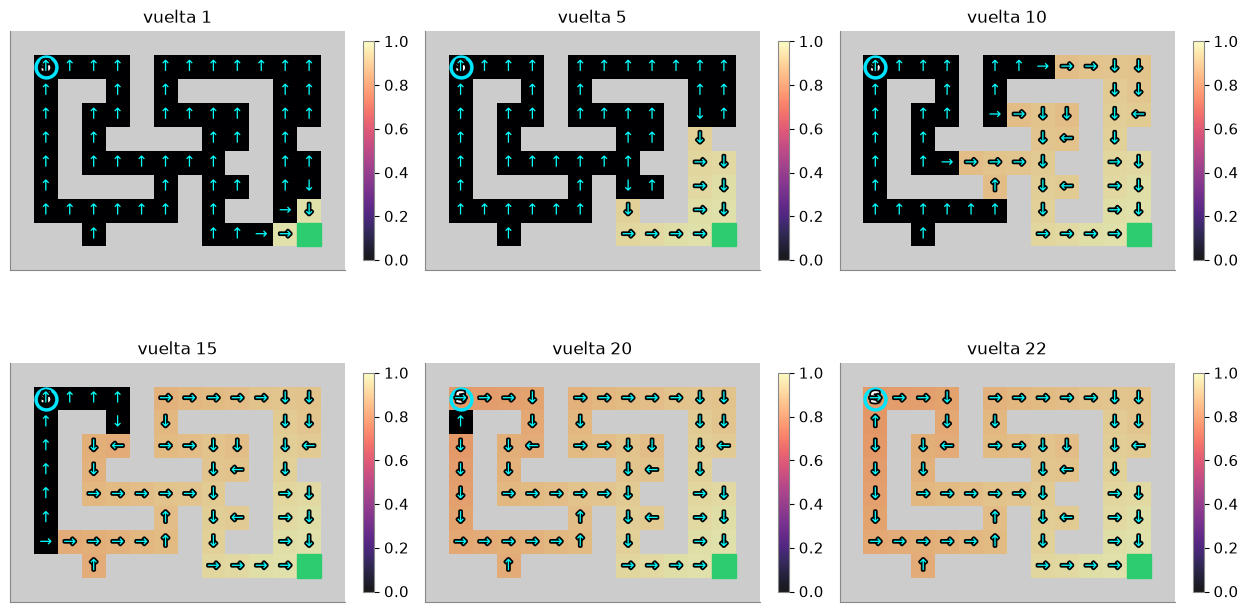

Iteración de valor: converge (cambio máximo < 1e-10) en 22 vueltas.
V*(S) = 0.8262   = 0.99^19 = 0.8262:  el camino óptimo desde S tiene 20 pasos
La casilla más lejana está a 21 pasos: V* = 0.8179
¿V*(s) = γ^(d−1) en todas las casillas? sí


In [13]:
hist_vi = iteracion_de_valor(env, GAMMA)
V_opt = hist_vi[-1]
pi_opt = valores_Q(env, V_opt, GAMMA).argmax(axis=1)
flechas_vi = [valores_Q(env, V, GAMMA).argmax(axis=1) for V in hist_vi]
ks = [1, 5, 10, 15, 20, len(hist_vi) - 1]
plot_row(env, [hist_vi[k] for k in ks], [f"vuelta {k}" for k in ks], policies=[flechas_vi[k] for k in ks],
         clim=(0, 1), size=4.2, ncols=3, marks=[env.start] * len(ks))

d = distancias(env)
camino_opt = partida(env, pi_opt)
print(f"Iteración de valor: converge (cambio máximo < 1e-10) en {len(hist_vi) - 1} vueltas.")
print(f"V*(S) = {V_opt[env.start]:.4f}   = 0.99^19 = {0.99 ** 19:.4f}:  el camino óptimo desde S tiene {len(camino_opt) - 1} pasos")
print(f"La casilla más lejana está a {d.max()} pasos: V* = {V_opt[np.argmax(d)]:.4f}")
print(f"¿V*(s) = γ^(d−1) en todas las casillas? {'sí' if np.allclose(V_opt[d > 0], GAMMA ** (d[d > 0] - 1.0)) else 'no'}")

En la vuelta $k$ tienen valor las casillas a $k$ pasos o menos de la salida, y ese valor ya es el definitivo: $\gamma^{d-1}$ para una casilla a $d$ pasos. Por eso converge apenas el frente llega a la casilla más lejana (y una vuelta más que confirma que nada cambia). Dibujemos la política óptima y el camino desde S.

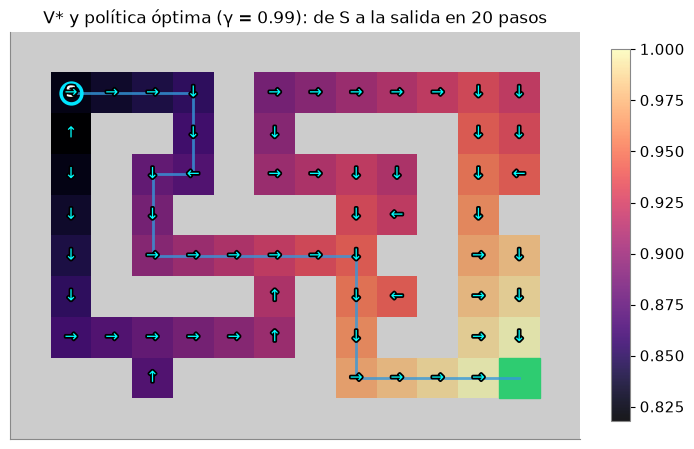

¿Coincide con la iteración de política? max |V* − V_PI| = 0.0e+00


In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_cave(env, values=V_opt, policy=pi_opt, path=camino_opt, ax=ax, mark=env.start,
          title=f"V* y política óptima (γ = {GAMMA}): de S a la salida en {len(camino_opt) - 1} pasos")
plt.show()
print(f"¿Coincide con la iteración de política? max |V* − V_PI| = {np.max(np.abs(V_opt - pi_desde_arriba[-1]['V'])):.1e}")

### Paso 2 — Comparar vueltas

¿Después de cuántas vueltas las flechas ya son óptimas? Para cada método, la fracción de casillas cuya flecha es óptima, vuelta por vuelta.

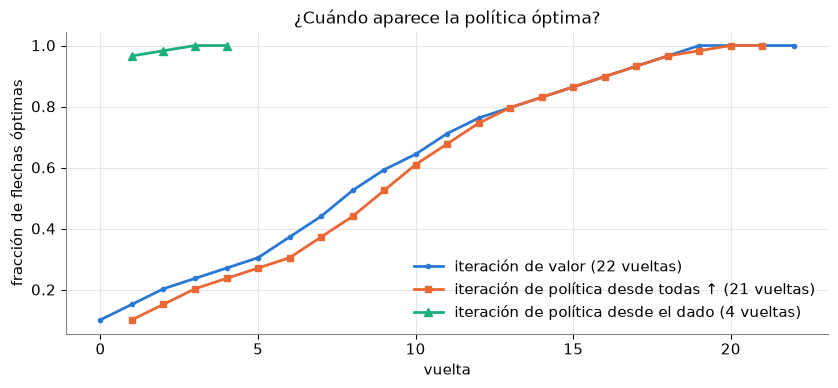

Iteración de valor: flechas óptimas desde la vuelta 19; valores convergidos en la vuelta 22.
Iteración de política desde todas ↑: 21 vueltas;  desde el dado: 4 vueltas.
Después de la primera mejora desde el dado, flechas óptimas: 97 %


In [15]:
frac_vi = [frac_optimas(env, p, opt) for p in flechas_vi]
frac_azar = [frac_optimas(env, v["nueva"], opt) for v in pi_desde_azar]
frac_arriba = [frac_optimas(env, v["nueva"], opt) for v in pi_desde_arriba]
k_flechas_vi = next(k for k, f in enumerate(frac_vi) if f == 1 and all(x == 1 for x in frac_vi[k:]))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(range(len(frac_vi)), frac_vi, "-o", ms=3, color=COLORES[0], label=f"iteración de valor ({len(hist_vi) - 1} vueltas)")
ax.plot(range(1, len(frac_arriba) + 1), frac_arriba, "-s", ms=4, color=COLORES[1],
        label=f"iteración de política desde todas ↑ ({len(pi_desde_arriba)} vueltas)")
ax.plot(range(1, len(frac_azar) + 1), frac_azar, "-^", ms=6, color=COLORES[2],
        label=f"iteración de política desde el dado ({len(pi_desde_azar)} vueltas)")
ax.set_xlabel("vuelta"); ax.set_ylabel("fracción de flechas óptimas")
ax.set_title("¿Cuándo aparece la política óptima?"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

print(f"Iteración de valor: flechas óptimas desde la vuelta {k_flechas_vi}; valores convergidos en la vuelta {len(hist_vi) - 1}.")
print(f"Iteración de política desde todas ↑: {len(pi_desde_arriba)} vueltas;  desde el dado: {len(pi_desde_azar)} vueltas.")
print(f"Después de la primera mejora desde el dado, flechas óptimas: {100 * frac_azar[0]:.0f} %")

Las dos recetas llegan a la misma política y al mismo $V^*$. La diferencia está en **qué hace cada vuelta**:

| | cada vuelta | vueltas en esta cueva |
|---|---|---|
| iteración de política | evalúa la política entera (un sistema de 60 ecuaciones) y después mejora | pocas desde el dado, muchas desde «todas ↑» |
| iteración de valor | un solo barrido de Bellman con el máximo, sin evaluar nada | tantas como pasos hasta la casilla más lejana, más una |

Las vueltas de la iteración de política son caras y pocas; las de la iteración de valor, baratas y muchas. En esta cueva de pasillos, si se arranca de una política que no ve la salida, las dos avanzan un tramo por vuelta.

## 7. Piso resbaloso, costo por paso y $\gamma$

Con el mapa podemos cambiar el mundo y recalcular todo en un instante. Tres perillas:

- **slip**: con esa probabilidad el agente se resbala hacia un costado (mitad a cada lado); si hay pared, choca y se queda.
- **costo por paso** (`step_reward`): un premio negativo en cada paso que no entra a la salida.
- **$\gamma$**: cuánto pesa el futuro.

### Paso 1 — El piso resbaloso: qué cambia en $P$, en $V^*$ y en las flechas

Acción ↓ en la casilla (1, 11):
   piso normal: (2, 11) con 1.00
   slip = 0.2 : (1, 10) con 0.10, (1, 12) con 0.10, (2, 11) con 0.80

V*(S): piso normal = 0.8262   slip 0.2 = 0.7742
Casillas donde la flecha óptima cambia con slip 0.2: 0
Vueltas de iteración de valor: piso normal = 22   slip 0.2 = 67


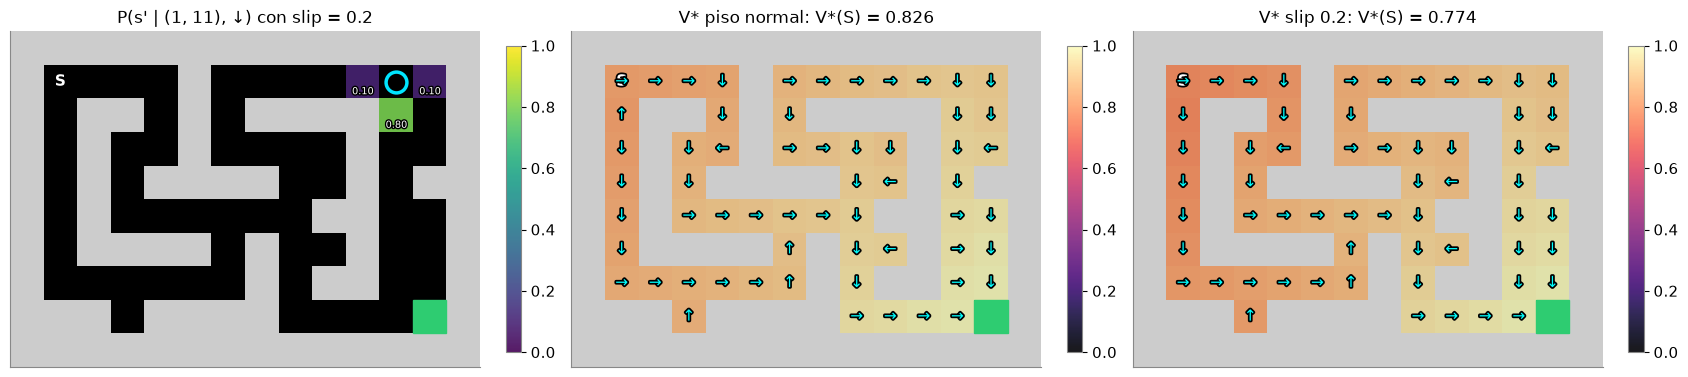

In [16]:
env_slip = CaveEnv(slip=0.2)
s_ej = env.pos2s[(1, 11)]                     # una casilla con espacio a los costados
print("Acción ↓ en la casilla (1, 11):")
print("   piso normal:", ", ".join(f"{env.free[s2]} con {p:.2f}" for s2, p in enumerate(env.P[s_ej, 2]) if p > 0))
print("   slip = 0.2 :", ", ".join(f"{env_slip.free[s2]} con {p:.2f}" for s2, p in enumerate(env_slip.P[s_ej, 2]) if p > 0))

hist_slip = iteracion_de_valor(env_slip, GAMMA)
V_slip = hist_slip[-1]
pi_slip = valores_Q(env_slip, V_slip, GAMMA).argmax(axis=1)
n_cambian = sum(not opt[s, pi_slip[s]] for s in range(env.nS) if s != env.goal)
print(f"\nV*(S): piso normal = {V_opt[env.start]:.4f}   slip 0.2 = {V_slip[env.start]:.4f}")
print(f"Casillas donde la flecha óptima cambia con slip 0.2: {n_cambian}")
print(f"Vueltas de iteración de valor: piso normal = {len(hist_vi) - 1}   slip 0.2 = {len(hist_slip) - 1}")

fig, axs = plt.subplots(1, 3, figsize=(17, 4.4))
plot_cave(env, values=np.where(env_slip.P[s_ej, 2] > 0, env_slip.P[s_ej, 2], np.nan), ax=axs[0], cmap="viridis",
          clim=(0, 1), mark=s_ej, numbers=True, title="P(s' | (1, 11), ↓) con slip = 0.2")
plot_cave(env, values=V_opt, policy=pi_opt, ax=axs[1], clim=(V_slip.min(), 1), title=f"V* piso normal: V*(S) = {V_opt[env.start]:.3f}")
plot_cave(env, values=V_slip, policy=pi_slip, ax=axs[2], clim=(V_slip.min(), 1), title=f"V* slip 0.2: V*(S) = {V_slip[env.start]:.3f}")
plt.tight_layout(); plt.show()

En esta cueva **las flechas no cambian**: no hay pozos ni peligros, así que resbalarse solo hace perder tiempo (casi siempre contra una pared del pasillo) y la mejor dirección sigue siendo la misma. Lo que baja es **el valor**: cuanto más lejos de la salida, más resbalones esperados en el camino. Y la iteración de valor tarda más vueltas: ahora hay caminos de todos los largos.

### Paso 2 — Doce partidas con y sin slip

Jugamos 12 partidas desde S con la política óptima de cada cueva y las dibujamos superpuestas (cada una corrida un poquito para que se distingan).

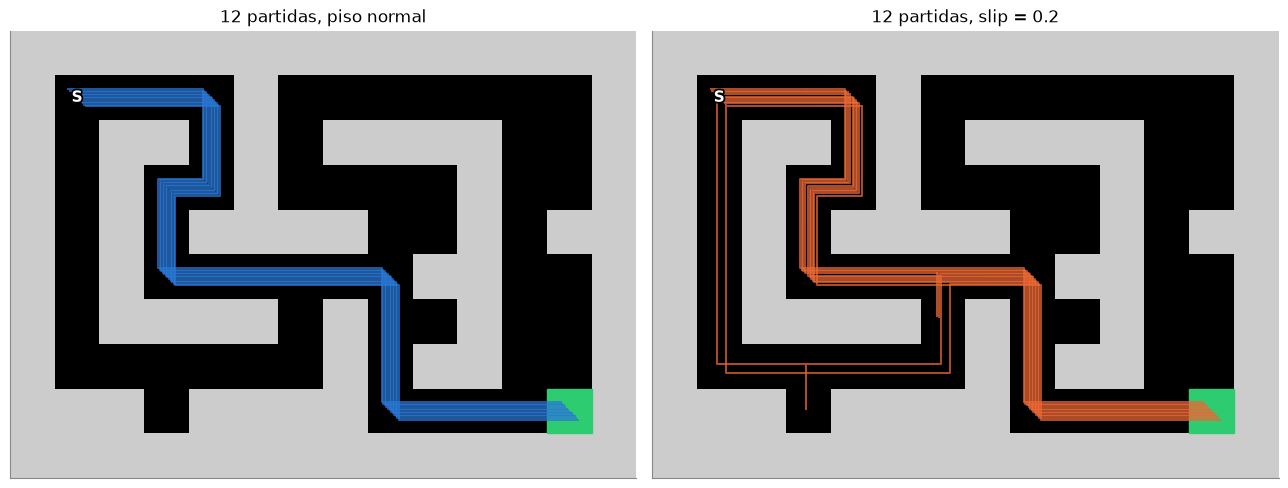

pasos, piso normal: [20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20]
pasos, slip 0.2   : [27, 24, 28, 27, 29, 26, 28, 21, 23, 24, 27, 27]   promedio = 25.9
retorno de cada partida con slip: 0.770, 0.794, 0.762, 0.770, 0.755, 0.778, 0.762, 0.818, 0.802, 0.794, 0.770, 0.770
promedio de los 12 retornos = 0.779   V*(S) con slip = 0.774


In [17]:
caminos_normal = [partida(env, pi_opt, semilla=k) for k in range(12)]
caminos_slip = [partida(env_slip, pi_slip, semilla=k) for k in range(12)]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
partidas_superpuestas(env, caminos_normal, axs[0], COLORES[0], "12 partidas, piso normal")
partidas_superpuestas(env, caminos_slip, axs[1], COLORES[1], "12 partidas, slip = 0.2")
plt.tight_layout(); plt.show()

largos_n = [len(c) - 1 for c in caminos_normal]; largos_s = [len(c) - 1 for c in caminos_slip]
print("pasos, piso normal:", largos_n)
print("pasos, slip 0.2   :", largos_s, f"  promedio = {np.mean(largos_s):.1f}")
G_s = [GAMMA ** (L - 1) for L in largos_s]
print(f"retorno de cada partida con slip: {', '.join(f'{g:.3f}' for g in G_s)}")
print(f"promedio de los 12 retornos = {np.mean(G_s):.3f}   V*(S) con slip = {V_slip[env.start]:.3f}")

Sin slip, las 12 partidas son **la misma**: 20 pasos, una sola línea. Con slip, cada partida es distinta y tarda distinto, aunque la política sea la misma. Por eso $V$ es un retorno **esperado**: el promedio sobre todas las partidas posibles (con 12 partidas, el promedio todavía se mueve bastante).

### Paso 3 — El costo por paso

Con $\gamma < 1$ el descuento ya apura al agente: llegar antes vale más. Para ver qué hace el costo por paso, sacamos el descuento ($\gamma = 1$) y comparamos sin costo y con un costo de $-0{,}01$ por paso.

γ = 1, sin costo         V*(S) = 1.0000   ¿todas las casillas valen lo mismo? sí   no llega en 60 pasos
γ = 1, costo −0.01       V*(S) = 0.8100   ¿todas las casillas valen lo mismo? no   llega en 20 pasos
γ = 0.99, costo −0.01    V*(S) = 0.6523   ¿todas las casillas valen lo mismo? no   llega en 20 pasos


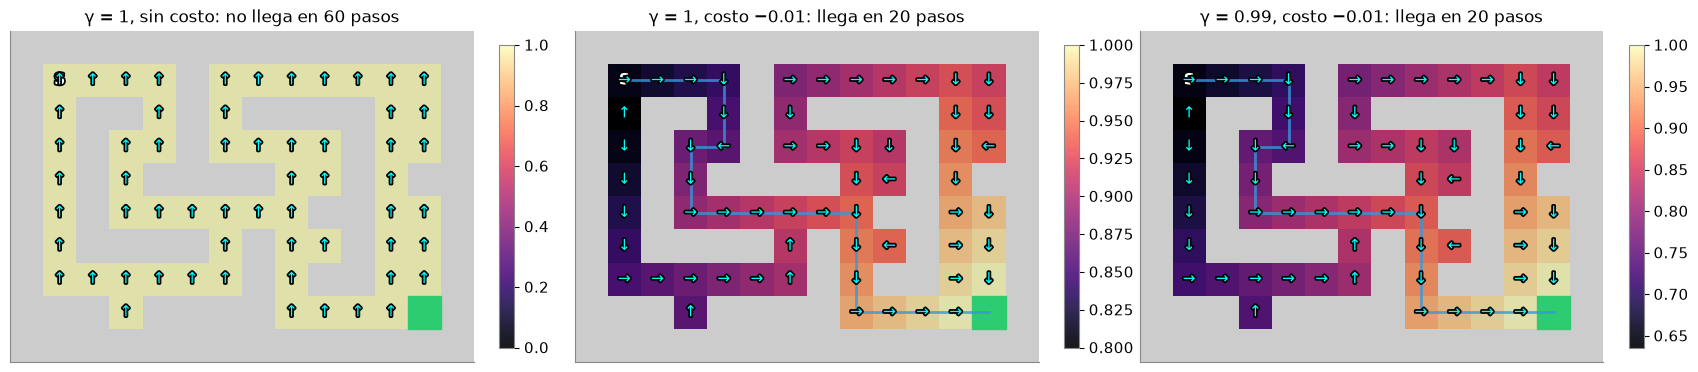

In [18]:
casos = [("γ = 1, sin costo", CaveEnv(step_reward=0.0), 1.0),
         ("γ = 1, costo −0.01", CaveEnv(step_reward=-0.01), 1.0),
         ("γ = 0.99, costo −0.01", CaveEnv(step_reward=-0.01), 0.99)]
fig, axs = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (nombre, e, g) in zip(axs, casos):
    V_c = iteracion_de_valor(e, g)[-1]
    pi_c = valores_Q(e, V_c, g).argmax(axis=1)
    cam = partida(e, pi_c, max_pasos=60)
    llega = f"llega en {len(cam) - 1} pasos" if cam[-1] == e.goal else "no llega en 60 pasos"
    plot_cave(e, values=V_c, policy=pi_c, path=cam, ax=ax, title=f"{nombre}: {llega}")
    print(f"{nombre:24s} V*(S) = {V_c[env.start]:.4f}   ¿todas las casillas valen lo mismo? "
          f"{'sí' if np.ptp(V_c[np.arange(env.nS) != env.goal]) < 1e-9 else 'no'}   {llega}")
plt.tight_layout(); plt.show()

Sin descuento y sin costo, **todas las casillas valen 1**: llegar ahora o dentro de mil pasos da lo mismo, todas las acciones empatan y el agente (que en un empate elige ↑) se queda chocando contra la pared de arriba de S. Con un costo por paso, cada paso de más resta: $V^*(S) = 1 - 19 \cdot 0{,}01 = 0{,}81$, y la política vuelve a ser el camino más corto. Con costo **y** descuento, las dos cosas apuran: $V^*(S)$ baja todavía más.

### Paso 4 — El descuento $\gamma$

Mismo mapa, mismo +1; solo cambia $\gamma$. Graficamos $V^*(s)$ contra la distancia a la salida.

γ = 0.5   V*(S) = 1.91e-06   flechas distintas de las de γ = 0.99: 0
γ = 0.9   V*(S) = 0.135   flechas distintas de las de γ = 0.99: 0
γ = 0.99  V*(S) = 0.826   flechas distintas de las de γ = 0.99: 0


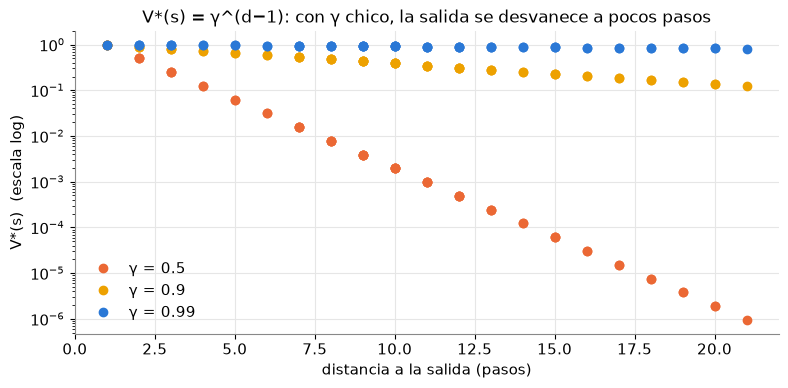

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
mask = np.arange(env.nS) != env.goal
for g, col in [(0.5, COLORES[1]), (0.9, COLORES[3]), (0.99, COLORES[0])]:
    V_g = iteracion_de_valor(env, g)[-1]
    pi_g = valores_Q(env, V_g, g).argmax(axis=1)
    distintas = sum(not opt[s, pi_g[s]] for s in range(env.nS) if s != env.goal)
    ax.semilogy(d[mask], V_g[mask], "o", color=col, label=f"γ = {g}")
    print(f"γ = {g:<5} V*(S) = {V_g[env.start]:.3g}   flechas distintas de las de γ = 0.99: {distintas}")
ax.set_xlabel("distancia a la salida (pasos)"); ax.set_ylabel("V*(s)  (escala log)")
ax.set_title("V*(s) = γ^(d−1): con γ chico, la salida se desvanece a pocos pasos")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

Con el mapa exacto las flechas son las mismas para los tres $\gamma$: alcanza con que la diferencia exista, aunque sea de $10^{-6}$. Pero con $\gamma = 0{,}5$ el valor de S es una millonésima: cuando en la clase 5 tengamos que **estimar** los valores jugando, con ruido, una diferencia así se pierde.

**Moraleja:** la recompensa dice *qué* queremos; $\gamma$ y el costo por paso dicen *con qué apuro*; el slip dice *cuánto podemos confiar* en que la acción haga lo que pedimos.

### ✍️ Ejercicio — Las tres perillas

Cambien `slip_ej`, `costo_ej` y `gamma_ej` y ejecuten. Antes de ejecutar, **predigan**: ¿bajará $V^*(S)$? ¿Cambiará alguna flecha? Prueben, por ejemplo, slip 0.5 con costo −0.05, y `bump_ej = -0.1` (castigo por chocar contra una pared).

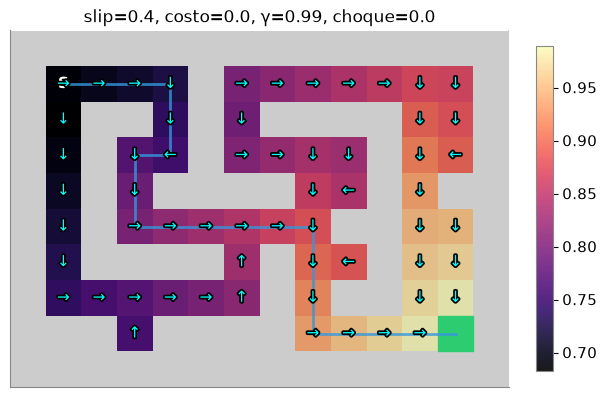

V*(S) = 0.6871   flechas distintas de la cueva normal: 0   vueltas: 118


In [20]:
slip_ej = 0.4     # TODO: probá 0, 0.2, 0.5
costo_ej = 0.0    # TODO: probá -0.01, -0.05
gamma_ej = 0.99   # TODO: probá 0.5, 0.9, 1.0 (con γ = 1 poné un costo)
bump_ej = 0.0     # TODO: probá -0.1

env_ej = CaveEnv(slip=slip_ej, step_reward=costo_ej, bump_reward=bump_ej)
h_ej = iteracion_de_valor(env_ej, gamma_ej)
V_ej = h_ej[-1]; pi_ej = valores_Q(env_ej, V_ej, gamma_ej).argmax(axis=1)
n_dist = sum(not opt[s, pi_ej[s]] for s in range(env.nS) if s != env.goal)
plot_cave(env_ej, values=V_ej, policy=pi_ej, path=partida(env_ej, pi_ej, semilla=1),
          title=f"slip={slip_ej}, costo={costo_ej}, γ={gamma_ej}, choque={bump_ej}")
plt.show()
print(f"V*(S) = {V_ej[env.start]:.4f}   flechas distintas de la cueva normal: {n_dist}   vueltas: {len(h_ej) - 1}")

## 8. El mismo molde fuera de la cueva: el robot de reciclaje

Un clásico de Sutton y Barto (ejemplo 3.3). Un robot junta latas vacías en una oficina. Su batería está **alta** o **baja**, y en cada turno elige:

- **buscar** latas: rinde $r_\text{buscar} = 2$. Con batería alta, sigue alta con probabilidad $\alpha$ (si no, pasa a baja). Con batería baja, sigue baja con probabilidad $\beta$; si no, **se agota**: hay que rescatarlo ($-3$) y vuelve recargado.
- **esperar** a que alguien le traiga una lata: rinde $r_\text{esperar} = 1$ y no gasta batería.
- **recargar** (solo con batería baja): vuelve a alta, sin premio.

Dos estados, tres acciones: es un MDP con su $(S, A, P, R, \gamma)$, igual que la cueva. Usamos $\gamma = 0{,}9$.

### Paso 1 — La tabla de la política

In [21]:
estados_r, acciones_r, transicion_r = robot(alfa=0.8, beta=0.4, r_buscar=2, r_esperar=1)
sol_robot = resolver_mdp(estados_r, acciones_r, transicion_r, gamma=0.9)

estado acción óptima      V*(s)   Q(s, buscar)   Q(s, esperar)   Q(s, recargar)
alta   buscar             16.95          16.95           16.25                —
baja   recargar           15.25          13.64           14.73            15.25

iteración de valor: 225 vueltas · iteración de política: 2 vueltas · ¿mismo V*? sí


Con batería alta, busca. Con batería baja, **recarga**: buscar arriesga un 60 % de quedar varado y pagar el rescate. «Recargar» con batería alta no está permitida (—).

### Paso 2 — ¿A partir de qué $\beta$ conviene buscar con batería baja?

Si buscar con batería baja casi nunca agota al robot ($\beta$ alto), arriesgarse vale la pena. Calculemos el **umbral** de $\beta$ y miremos cómo cambia con $\alpha$ y con la recompensa por esperar.

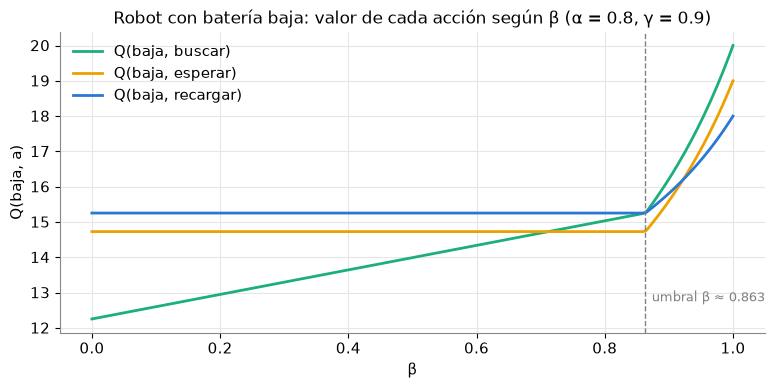

Con α = 0.8, r_esperar = 1: con batería baja conviene buscar si β > 0.863; si no, recargar.
   α = 0.5   umbral β = 0.798


   α = 0.8   umbral β = 0.863


   α = 0.95  umbral β = 0.915
   r_esperar = 0.0  acción con batería baja y β = 0.4: recargar
   r_esperar = 1.0  acción con batería baja y β = 0.4: recargar
   r_esperar = 1.5  acción con batería baja y β = 0.4: recargar
   r_esperar = 2.0  acción con batería baja y β = 0.4: esperar


Con β = 0.4, a partir de r_esperar ≈ 1.53 el robot con batería baja espera en vez de recargar.


In [22]:
betas = np.linspace(0, 1, 201)
Qb = np.array([robot_resuelto(0.9, alfa=0.8, beta=b)[2][1] for b in betas])     # Q(baja, ·)
b_star = umbral_beta(0.9, alfa=0.8)

fig, ax = plt.subplots(figsize=(8, 4))
for j, (nombre, col) in enumerate(zip(acciones_r, [COLORES[2], COLORES[3], COLORES[0]])):
    ax.plot(betas, Qb[:, j], color=col, label=f"Q(baja, {nombre})")
ax.axvline(b_star, color="gray", ls="--", lw=1)
ax.text(b_star + 0.01, Qb.min() + 0.5, f"umbral β ≈ {b_star:.3f}", color="gray", fontsize=9)
ax.set_xlabel("β"); ax.set_ylabel("Q(baja, a)"); ax.legend(frameon=False)
ax.set_title("Robot con batería baja: valor de cada acción según β (α = 0.8, γ = 0.9)")
plt.tight_layout(); plt.show()

print(f"Con α = 0.8, r_esperar = 1: con batería baja conviene buscar si β > {b_star:.3f}; si no, recargar.")
for a_ in [0.5, 0.8, 0.95]:
    print(f"   α = {a_:<4}  umbral β = {umbral_beta(0.9, alfa=a_):.3f}")
for rw in [0.0, 1.0, 1.5, 2.0]:
    print(f"   r_esperar = {rw:<4} acción con batería baja y β = 0.4: {robot_resuelto(0.9, alfa=0.8, beta=0.4, r_esperar=rw)[1][1]}")
rws = np.linspace(0, 2.5, 2501)
rw_star = rws[next(i for i, rw in enumerate(rws) if robot_resuelto(0.9, alfa=0.8, beta=0.4, r_esperar=rw)[1][1] == "esperar")]
print(f"Con β = 0.4, a partir de r_esperar ≈ {rw_star:.2f} el robot con batería baja espera en vez de recargar.")

### Paso 3 — El mapa de decisiones

Variamos $\beta$ y la recompensa por esperar, y pintamos la acción óptima con batería baja.

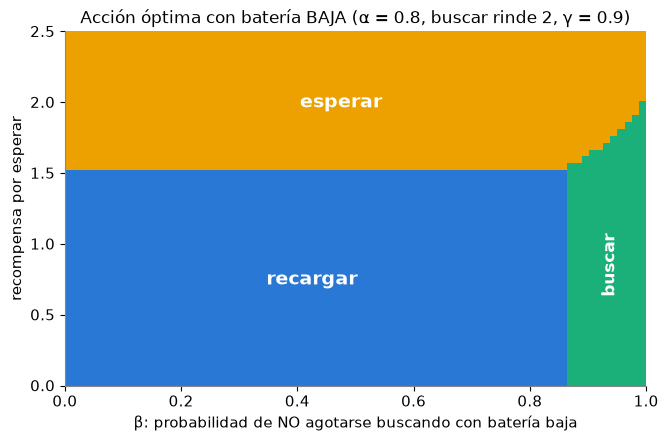

In [23]:
mapa_robot(gamma=0.9, alfa=0.8)

Tres regiones con sentido común: si buscar con batería baja casi nunca agota al robot, **busca**; si esperar rinde casi tanto como buscar, **espera** (no arriesga y no pierde un turno recargando); en el resto, **recarga**. Nadie programó estas reglas: salen de resolver el MDP.

El tutor de la clase 2 también se puede plantear así: el estado es lo que sabe el alumno, las acciones son los problemas que elige el tutor, y la recompensa es lo que decidimos premiar.

## ✍️ Ejercicio — Planteen su propio MDP chiquito y resuélvanlo

Elijan un problema con **3 a 5 estados** y 2 o 3 acciones (por ejemplo: regar o no una planta según qué tan seca está; estudiar, descansar o salir según el cansancio; un tutor que elige un problema fácil o difícil según el nivel del alumno). Escriban:

1. los estados y las acciones;
2. la función `mi_transicion(s, a)`, que devuelve una lista de `(probabilidad, estado siguiente, recompensa)` (las probabilidades tienen que sumar 1; una lista vacía quiere decir que esa acción no se puede hacer en ese estado);
3. el $\gamma$.

`resolver_mdp` lo resuelve con iteración de valor y con iteración de política, y muestra la tabla. Abajo hay un ejemplo (la planta) para reemplazar.

Preguntas: ¿la política tiene sentido? ¿Qué parámetro la hace cambiar? ¿Cómo podría el agente «hacer trampa» con su recompensa?

In [24]:
# TODO: reemplazar por su MDP
MIS_ESTADOS = ["seca", "bien", "ahogada"]
MIS_ACCIONES = ["regar", "no regar"]
MI_GAMMA = 0.9

def mi_transicion(s, a):
    # lista de (probabilidad, estado siguiente, recompensa)
    if s == "seca":
        return [(0.9, "bien", 1.0), (0.1, "seca", -1.0)] if a == "regar" else [(1.0, "seca", -1.0)]
    if s == "bien":
        return [(0.7, "bien", 1.0), (0.3, "ahogada", -1.0)] if a == "regar" else [(0.6, "bien", 1.0), (0.4, "seca", -1.0)]
    if s == "ahogada":
        return [(1.0, "ahogada", -1.0)] if a == "regar" else [(0.5, "bien", 1.0), (0.5, "ahogada", -1.0)]

mi_sol = resolver_mdp(MIS_ESTADOS, MIS_ACCIONES, mi_transicion, gamma=MI_GAMMA)

estado    acción óptima      V*(s)   Q(s, regar)   Q(s, no regar)
seca      regar               4.17          4.17             2.76
bien      no regar            3.70          3.55             3.70
ahogada   no regar            3.03          1.73             3.03

iteración de valor: 211 vueltas · iteración de política: 2 vueltas · ¿mismo V*? sí


**Lo que encontramos** (¿la política tiene sentido? ¿qué parámetro la cambia? ¿cómo se podría hacer trampa con la recompensa?):

-

## Preguntas para pensar

1. Con el mapa a la vista, planificar es preguntar en cada casilla qué pasaría con cada acción, quedarse con la mejor y repetir hasta que nada cambie. ¿En qué se parecen y en qué se diferencian la iteración de política y la de valor, dicho con esa oración?
2. En la cueva, el piso resbaloso no cambió ninguna flecha. Inventen un cambio en la cueva (un pozo, una pared que duele, un atajo angosto) con el que el slip **sí** cambie la mejor flecha en alguna casilla.
3. Todo lo de hoy usó `env.P` y `env.R`. Un jugador en la cueva a oscuras no los tiene. ¿Qué información sí tiene después de cada paso, y cómo podría usarla para estimar $V$?

## Próxima clase

Todo esto pidió conocer $P$ y $R$. ¿Y si no tenemos el mapa? En la clase 5 **evaluamos sin mapa, jugando**: Monte Carlo promedia partidas enteras y la diferencia temporal (TD) aprende paso a paso. Es la misma diferencia que vimos en la clase 3 entre resolver Bellman con $P$ y promediar muchas caminatas.